In [ ]:
%viz

UsageError: Line magic function `%viz` not found.


In [ ]:
library package DigtialTwin{

    private connection def ComponentDataBaseConnection{
            end port componentEnd:LibTwin::LibTwinEntity::LibTwinComponent::MeasurePort;
            attribute protocoll:Protocol;
            end port dataBaseEnd:~LibTwin::LibTwinEntity::LibTwinComponent::MeasurePort;

        }
    
    abstract part def LibTwin{
        abstract part entities:LibTwinEntity[0..*];
        abstract part dataBases:LibTwinDataBase[0..*];
        abstract part dataBaseComponentConnections:ComponentDataBaseConnection[0..*];

        abstract part def LibTwinEntity{
            abstract part def LibTwinComponent{

                abstract port def MeasurePort{
                    abstract attribute data:LibDTAttributes[0..*];
                }
                attribute def LibDTAttributes{
                    attribute attributeDataType:AttributeDataType;
                }
                abstract port measurements:MeasurePort[0..*];
            }
            
            attribute def ConstAttributes specializes LibTwinComponent::LibDTAttributes{
            attribute value:ScalarValues::String;
            }

            abstract attribute constAttributes:ConstAttributes[0..*];
            abstract part subEntities:LibTwinEntity[0..*];
            abstract part components:LibTwinComponent[0..*];
            abstract action strategies:LibTwinConditionAction[0..*];

            abstract action def LibTwinConditionAction{
                in abstract attribute leftOperand:LibTwinComponent::LibDTAttributes;
                abstract attribute operator:ComparisonOperator;
                in abstract attribute rightOperand:LibTwinComponent::LibDTAttributes;
                out abstract attribute result:ScalarValues::Boolean;
                abstract part strategieActions:LibTwinStrategyAction[0..*];

                abstract part def LibTwinStrategyAction{
                    abstract attribute name:ScalarValues::String;
                    abstract attribute description:ScalarValues::String;
                    abstract attribute pathToCode:ScalarValues::String;
                    abstract attribute strategyType:StrategyType;
                }
            }
        }

        abstract part def LibTwinDataBase{
            abstract attribute libTwinDataBaseTier:LibTwinDataBaseTier;
            abstract attribute libTwinDataBaseType:LibTwinDataBaseType;
            port componentMeasurements:~LibTwinEntity::LibTwinComponent::MeasurePort[0..*];
        }

    }

    enum def AttributeDataType{
        STRING;
        DOUBLE;
        INTEGER;
    }

    enum def LibTwinDataBaseTier{
        HOT;
        COLD;
    }

    enum def LibTwinDataBaseType{
        RELATIONAL;
        TIMESERIES;
    }

    enum def Protocol{
        MQTT;
        REST;
        GRPC;
    }

    enum def ComparisonOperator{
        GREATER_THAN;
        LESS_THAN;
        EQUAL;
        GREATER_EQUAL;
        LESS_EQUAL;
        NOT_EQUAL;
    }
    enum def StrategyType{
        LAMBDA;
        CONTAINER;
    }
}



LibraryPackage DigtialTwin (afee3f6a-4b12-470a-9bec-24853e9a6000)


In [ ]:
package MicroGrid{

    private import DigtialTwin::*;


    

    part def MicroGridDigitalTwin specializes LibTwin{
        
        part def CommonEntity specializes LibTwinEntity{
            attribute maxConsumption:>constAttributes{
                attribute :>>value default "23.0";
                attribute:>>attributeDataType default AttributeDataType::DOUBLE;
            }

            part def PAC_Sensor specializes LibTwinComponent{
                port consumptionPort :>measurements{
                    attribute :>>data{
                        attribute:>>attributeDataType default AttributeDataType::DOUBLE;
                    }
                }
            }
            part sensor:>components:PAC_Sensor;
        }
        part MicroGridEntity:>entities{
            part battery:Battery:>subEntities{
                attribute :>>maxConsumption{
                    attribute :>>value = "3.0";
                }
                part p12:>>batterySensor;
            }
            part sieVercharge:Charger:>subEntities{
                attribute :>>maxConsumption{
                    attribute :>>value = "10.0";
                }
                part p13:>>chargerSensor;
            }

            part kebaP30:Charger:>subEntities{
                attribute :>>maxConsumption{
                    attribute :>>value = "22.0";
                }
                part p14:>>chargerSensor;
            }
        }

        part :> dataBases{
                attribute :>>libTwinDataBaseTier default LibTwinDataBaseTier::HOT;
                attribute :>>libTwinDataBaseType default LibTwinDataBaseType::RELATIONAL;
            
        }
        part :>dataBaseComponentConnections{
            end :>>componentEnd references MicroGridEntity.battery.p12.consumptionPort;
            attribute :>>protocoll default Protocol::MQTT;
            end :>>dataBaseEnd references dataBases.componentMeasurements;
        }


        

        part def Charger specializes CommonEntity{
            attribute:>maxConsumption{
                attribute:>>value default "11.0";
            }

            part chargerSensor:>sensor;
        }

        part def Battery specializes CommonEntity{
            attribute:>maxConsumption{
                attribute:>>value default "5.0";
            }
            part batterySensor:>sensor;
        }



    }
}

Package MicroGrid (c8b000cd-7342-41d8-9819-95063a05d343)


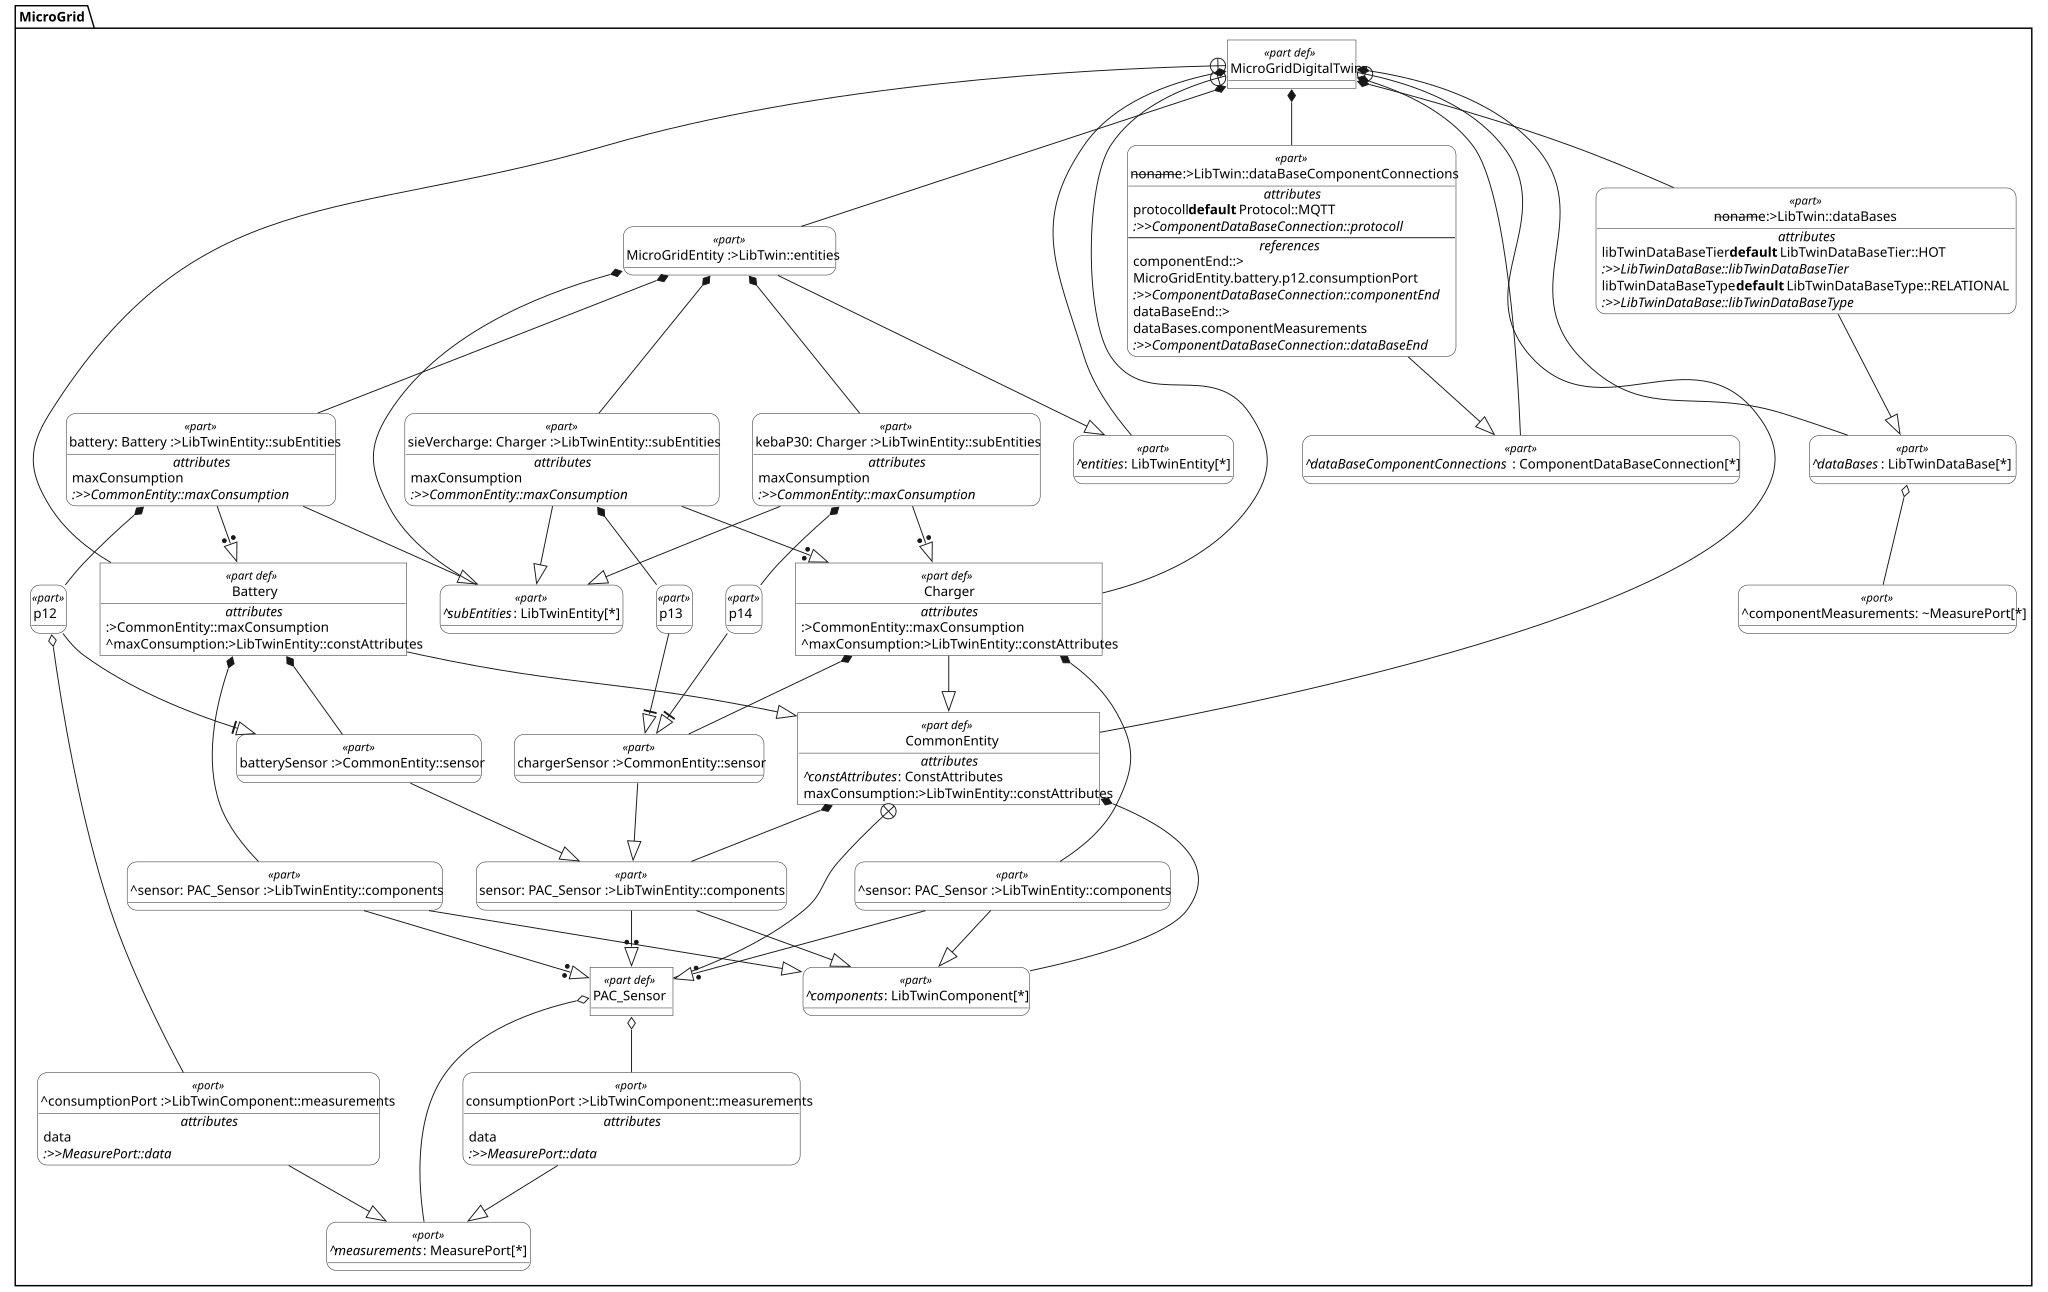

In [ ]:
%viz --view=TREE MicroGrid

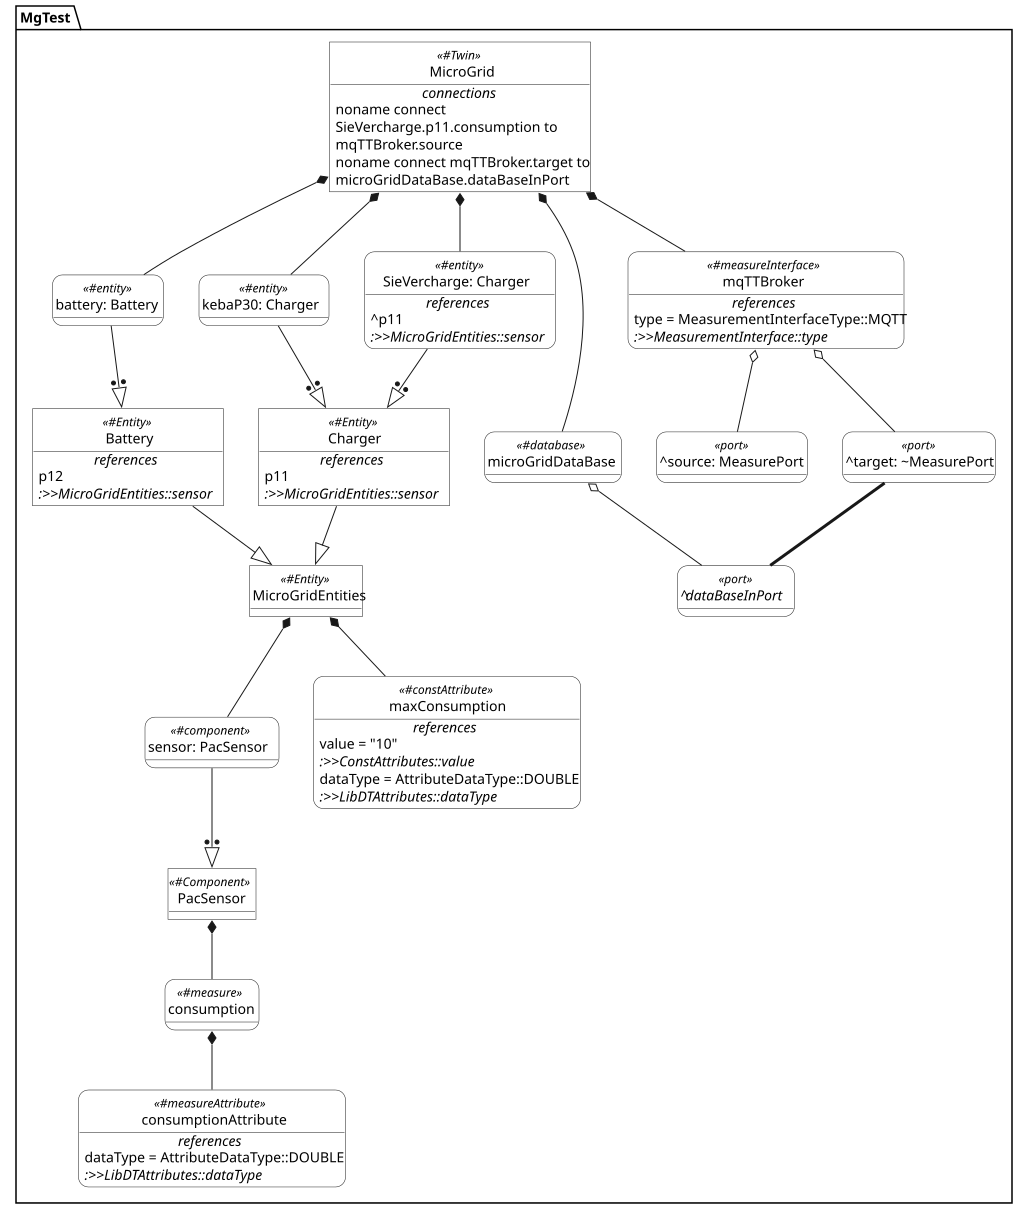

In [ ]:
%viz --view=TREE MgTest

In [ ]:
package MicroGridTwinPackage {
    private import DigitalTwinLibrary::*;


    part def PAC_Sensor specializes LibTwinComponent{
        out port powerConsumption redefines measureAttributes;
    }


    part def Charger specializes LibTwinEntity{
        attribute MaxConsumption:ConstAttributes :>> const_attributes {
                attribute :>> dataType = AttributeDataType::DOUBLE;
                attribute :>> value = "3453";
            }
        part sensor:PAC_Sensor redefines components{
            out port consumptionPort redefines powerConsumption{
                        out attribute :>> measurement {
                            attribute :>> dataType = AttributeDataType::DOUBLE;
                        }
                    }
        }
        perform action stopCharging redefines strategies{
            attribute :>>operator = ComparisonOperator::GREATER_THAN;
            in attribute :>>rightOperand = sensor.consumptionPort.measurement;
            in attribute :>>leftOperand = MaxConsumption;
            part stopChargingStrategy redefines strategieActions{
                attribute :>> name = "Stop Charging";
                attribute :>> type = StrategyType::LAMBDA;
                attribute :>> description = "Stops the charging";
                attribute :>> pathToCode = "\\path\\to";
            }
        }
    }

    interface def MQTTBroker specializes MeasurementInterface{
        attribute :>> type = MeasurementInterfaceType::MQTT;
    }

    part def MicroGridTwin specializes LibDTwin {
        
        attribute :>> name = "MicroGridTwin";
        part MicroGrid redefines libTwinEntities {

            attribute MaxConsumption:ConstAttributes :>> const_attributes {
                attribute :>> dataType = AttributeDataType::DOUBLE;
                attribute :>> value = "345";
            }

            attribute MinConsumption:ConstAttributes :>> const_attributes {
                attribute :>> dataType = AttributeDataType::DOUBLE;
                attribute :>> value = "120";
            }
            part Battery redefines subEntities{
                attribute MaxConsumption:ConstAttributes :>> const_attributes{
                    attribute :>> dataType = AttributeDataType::DOUBLE;
                    attribute :>> value = "76233";
                }
            }
            part SieVercharge:Charger redefines subEntities{
                attribute MaxConsumption:ConstAttributes redefines const_attributes {
                    attribute :>> value = "23.5";
                }
                part P12Sensor redefines sensor;
            }

            part KebaP30:Charger redefines subEntities{
                attribute MaxConsumption:ConstAttributes redefines const_attributes {
                    attribute :>> value = "3453.5";
                }
                part P13Sensor redefines sensor;
            }

        }

        part TimeSeriesDB:LibTwinDataBase redefines dataBases{
            attribute :>> dataBaseTier = LibTwinDataBaseTier::HOT;
            attribute :>> dataBaseType = LibTwinDataBaseType::TIMESERIES;
        }
        

        interface :MQTTBroker subsets measurementInterfaces 
        connect source ::> MicroGrid.SieVercharge.P12Sensor.consumptionPort 
            to target ::> TimeSeriesDB.measureAttributes;

        interface :MQTTBroker subsets measurementInterfaces 
        connect source ::> MicroGrid.KebaP30.P13Sensor.consumptionPort 
            to target ::> TimeSeriesDB.measureAttributes;
    }
}


Package MicroGridTwinPackage (2e7fc3f4-114a-43b1-93e6-8b6965c4fa30)


In [ ]:
package MicroGridTwinWithSubsetPackage {
    private import DigitalTwinLibrary::*;


    part def PAC_Sensor specializes LibTwinComponent{
        out port powerConsumption subsets measureAttributes;
    }


    part def Charger specializes LibTwinEntity{
        attribute MaxConsumption:ConstAttributes :>> const_attributes {
                attribute :>> dataType = AttributeDataType::DOUBLE;
                attribute :>> value = "3453";
            }
        part sensor:PAC_Sensor subsets components{
            out port consumptionPort redefines powerConsumption{
                        out attribute :>> measurement {
                            attribute :>> dataType = AttributeDataType::DOUBLE;
                        }
                    }
        }
        perform action stopCharging subsets strategies{
            attribute :>>operator = ComparisonOperator::GREATER_THAN;
            in attribute :>>rightOperand = sensor.consumptionPort.measurement;
            in attribute :>>leftOperand = MaxConsumption;
            part stopChargingStrategy subsets strategieActions{
                attribute :>> name = "Stop Charging";
                attribute :>> type = StrategyType::LAMBDA;
                attribute :>> description = "Stops the charging";
                attribute :>> pathToCode = "\\path\\to";
            }
        }
    }

    interface def MQTTBroker specializes MeasurementInterface{
        attribute :>> type = MeasurementInterfaceType::MQTT;
    }

    part def MicroGridTwin specializes LibDTwin {
        
        attribute :>> name = "MicroGridTwin";
        part MicroGrid subsets libTwinEntities {
            attribute MaxConsumption:ConstAttributes :>> const_attributes {
                attribute :>> dataType = AttributeDataType::DOUBLE;
                attribute :>> value = "345";
            }

            attribute MinConsumption:ConstAttributes :>> const_attributes {
                attribute :>> dataType = AttributeDataType::DOUBLE;
                attribute :>> value = "120";
            }
            part Battery subsets subEntities{
                attribute MaxConsumption:ConstAttributes :>> const_attributes{
                    attribute :>> dataType = AttributeDataType::DOUBLE;
                    attribute :>> value = "76233";
                }
            }
            part SieVercharge:Charger subsets subEntities{
                attribute MaxConsumption:ConstAttributes redefines const_attributes {
                    attribute :>> dataType = AttributeDataType::DOUBLE;
                    attribute :>> value = "23.5";
                }
                part P12Sensor redefines sensor;
            }

            part KebaP30:Charger subsets subEntities{
                attribute MaxConsumption:ConstAttributes redefines const_attributes {
                    attribute :>> value = "3453.5";
                }
                part P13Sensor subsets sensor;
            }

        }

        part TimeSeriesDB:LibTwinDataBase subsets dataBases{
            attribute :>> dataBaseTier = LibTwinDataBaseTier::HOT;
            attribute :>> dataBaseType = LibTwinDataBaseType::TIMESERIES;
        }
        

        interface :MQTTBroker subsets measurementInterfaces 
        connect source ::> MicroGrid.SieVercharge.P12Sensor.consumptionPort 
            to target ::> TimeSeriesDB.measureAttributes;

        interface :MQTTBroker subsets measurementInterfaces 
        connect source ::> MicroGrid.KebaP30.P13Sensor.consumptionPort 
            to target ::> TimeSeriesDB.measureAttributes;
    }
}


Package MicroGridTwinWithSubsetPackage (232dcad7-896c-419c-98e1-a43a0cc0288e)


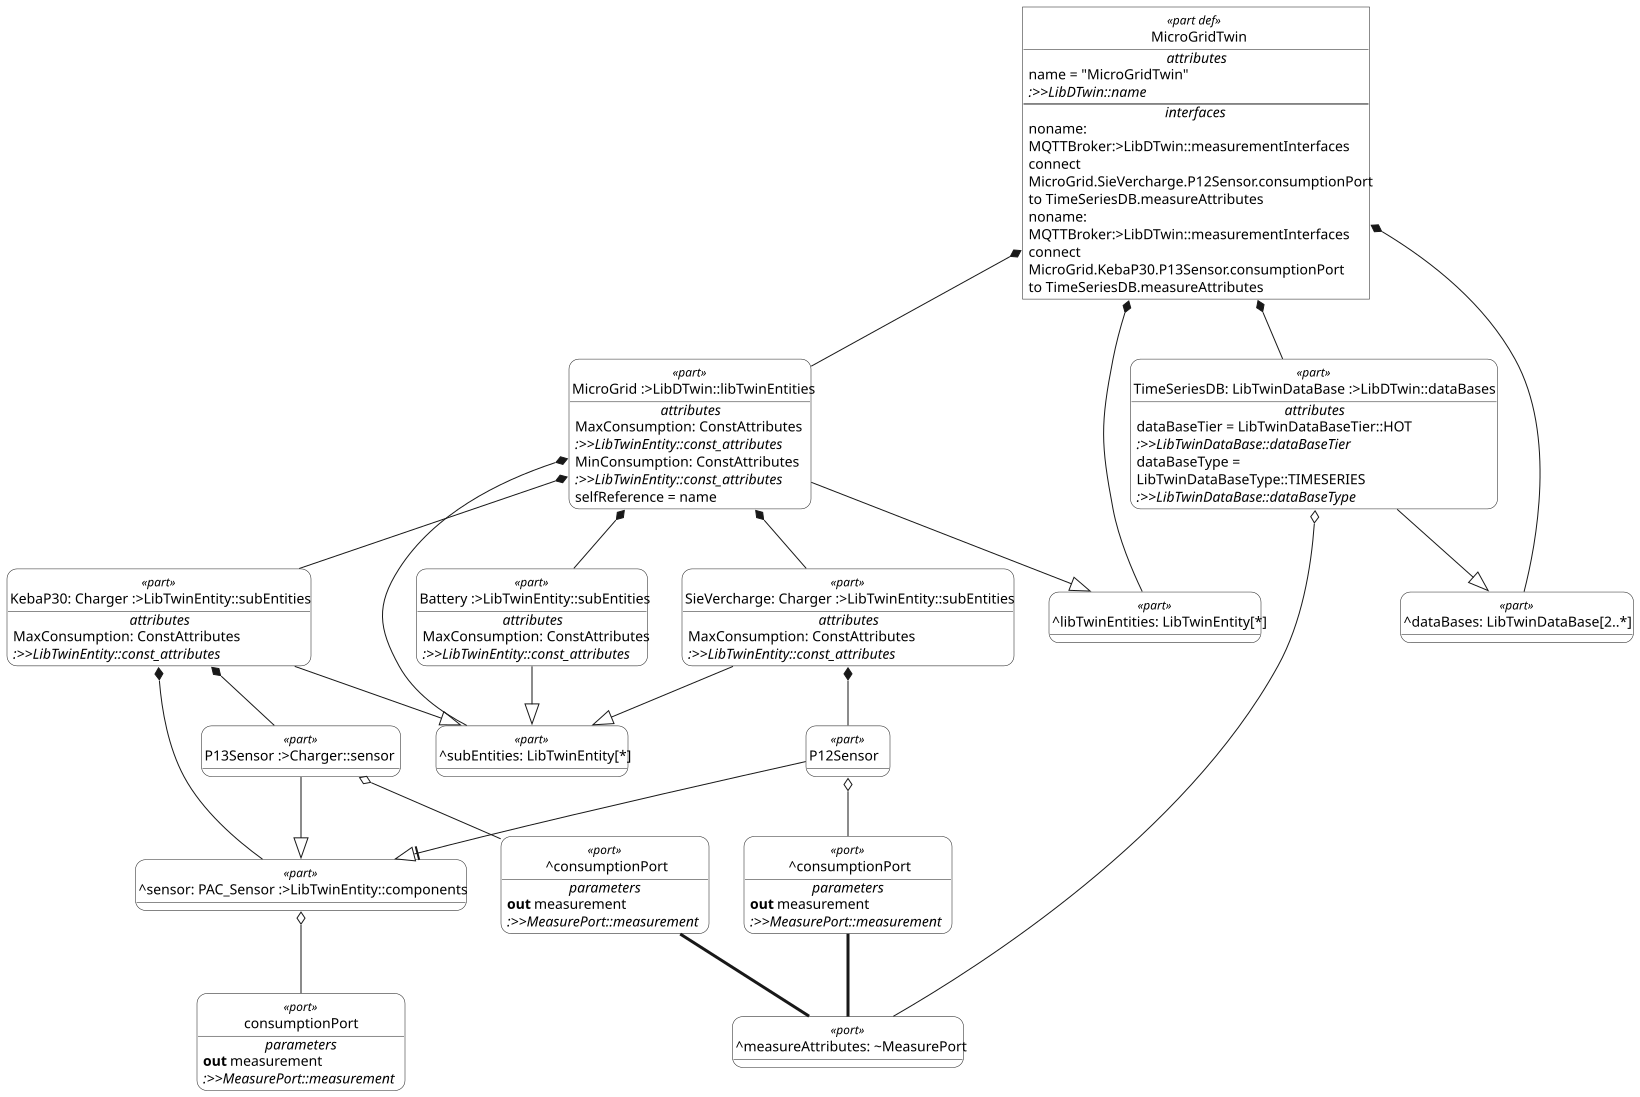

In [ ]:
%viz --view=TREE MicroGridTwinWithSubsetPackage::MicroGridTwin 

In [ ]:
package RD {

	part def Wheels{
		attribute test;
	}
	part def Wheels2{

	}
	part def Vehicle {
		part eng : Engine;
		part wheels[4]:Wheels;
	}

	part def SmallVehicle :> Vehicle {
		part smallEng : SmallEngine subsets eng;
		part smallEng2 : SmallEngine subsets eng;
	}

	part def Truck specializes Vehicle{
		part frontWheels:Wheels2:>>wheels{
			:>> test = "Hallo";
		}
		
	}
	part def BigVehicle :> Vehicle {
		part bigEng : BigEngine :>> eng;
	}

	part def Engine {
		part cyl : Cylinder[4..6];
	}
	part def CompleteOtherEngine{

	}
	part def SmallEngine :> CompleteOtherEngine{
	}
	part def BigEngine :> Engine {
		part subsets cyl[3];
	}

	part def Cylinder;
}



Package RD (0b9c5d89-e03b-4d91-aabe-07363a9cee04)


In [ ]:
%publish --view=TREE RD 

: 

In [ ]:
library package DigitalTwinLibrary{

    abstract part libTwinEntities:LibTwinEntity[0..*];
    abstract part dataBases:LibTwinDataBase[0..*];
    abstract interface measurementInterfaces:MeasurementInterface[0..*];
    abstract part def LibTwin{
        abstract part redefines libTwinEntities;
        abstract part redefines dataBases;
        abstract interface redefines measurementInterfaces;
    }
    abstract attribute const_attributes:ConstAttributes[0..*];
    abstract part sbEntities:LibTwinEntity[0..*];
    abstract part cmponents:LibTwinComponent[0..*];
    abstract action strategies:LibTwinConditionAction[0..*];
    
    abstract part def LibTwinEntity{
        abstract attribute redefines const_attributes;
        abstract part redefines sbEntities;
        abstract part redefines cmponents;
        abstract action redefines strategies;
        

    }
    
    out abstract port measurements:MeasurePort[0..*];
    abstract part def LibTwinComponent{
        out abstract port measures redefines measurements;
    }
    abstract attribute libTwinDataBaseTier:LibTwinDataBaseTier;
    abstract attribute libTwinDataBaseType:LibTwinDataBaseType;
    in abstract port dataBaseInPort:~MeasurePort;
    abstract part def LibTwinDataBase{
        abstract attribute redefines libTwinDataBaseTier;
        abstract attribute redefines libTwinDataBaseType;
        in abstract port redefines dataBaseInPort;
    }
    abstract attribute type:MeasurementInterfaceType;
    abstract interface def MeasurementInterface{
        abstract attribute redefines type; 
        end source : MeasurePort;
        end target : ~MeasurePort;
    }
    abstract attribute leftOperand:LibDTAttributes;
    abstract attribute operator:ComparisonOperator;
    abstract attribute rightOperand:LibDTAttributes;
    abstract attribute result:ScalarValues::Boolean;
    abstract part strategieActions:LibTwinStrategyAction[0..*];
    abstract action def LibTwinConditionAction{
        abstract attribute redefines leftOperand;
        abstract attribute redefines operator;
        abstract attribute redefines rightOperand;
        abstract attribute redefines result;
        abstract part redefines strategieActions;
    }
    abstract attribute name:ScalarValues::String;
    abstract attribute description:ScalarValues::String;
    abstract attribute pathToCode:ScalarValues::String;
    abstract attribute strategyType:StrategyType;
    abstract part def LibTwinStrategyAction{
        abstract attribute redefines name;
        abstract attribute redefines description;
        abstract attribute redefines pathToCode;
        abstract attribute redefines strategyType;
    }

    enum def AttributeDataType{
        STRING;
        DOUBLE;
        INTEGER;
    }
    attribute def LibDTAttributes{
        attribute dataType:AttributeDataType;
    }

    attribute def ConstAttributes specializes LibDTAttributes{
        attribute value:ScalarValues::String;
    }
    
    abstract attribute measurement:LibDTAttributes[0..*];
    port def MeasurePort{
        abstract attribute redefines measurement;
    }



    enum def LibTwinDataBaseTier{
        HOT;
        COLD;
    }

    enum def LibTwinDataBaseType{
        RELATIONAL;
        TIMESERIES;
    }

    enum def MeasurementInterfaceType{
        MQTT;
        REST;
        GRPC;
    }

    enum def ComparisonOperator{
        GREATER_THAN;
        LESS_THAN;
        EQUAL;
        GREATER_EQUAL;
        LESS_EQUAL;
        NOT_EQUAL;
    }
    enum def StrategyType{
        LAMBDA;
        CONTAINER;
    }

}


LibraryPackage DigitalTwinLibrary (9be40a2c-c9da-4332-b854-e5dd90d9e4df)


In [ ]:
package MetaModelDigitalTwin {

    private import DigitalTwinLibrary::*;
    private import Metaobjects::SemanticMetadata;
    public import DigitalTwinLibrary::AttributeDataType;
    public import DigitalTwinLibrary::MeasurementInterfaceType;
    public import DigitalTwinLibrary::LibTwinDataBaseTier;
    public import DigitalTwinLibrary::LibTwinDataBaseType;
    public import DigitalTwinLibrary::ComparisonOperator;
    public import DigitalTwinLibrary::StrategyType;

    metadata def testr specializes SemanticMetadata{

    }
    metadata def Twin specializes SemanticMetadata {
        redefines baseType = LibTwin meta SysML::PartDefinition;
        subsets annotatedElement : SysML::Definition;
        
    }

    metadata def Entity specializes SemanticMetadata{
        redefines baseType = LibTwinEntity meta SysML::PartDefinition;
        subsets annotatedElement : SysML::Definition;
    }

    metadata def entity specializes SemanticMetadata{
        redefines baseType = libTwinEntities meta SysML::PartUsage;
        subsets annotatedElement : SysML::Usage;
    }
    
    metadata def Component specializes SemanticMetadata{
        redefines baseType = LibTwinComponent meta SysML::PartDefinition;
        subsets annotatedElement : SysML::Definition;
    }

    metadata def component specializes SemanticMetadata{
        redefines baseType = cmponents meta SysML::PartUsage;
        subsets annotatedElement : SysML::Usage;
    }

    metadata def DataBase specializes SemanticMetadata{
        redefines baseType =LibTwinDataBase meta SysML::PartDefinition;
        subsets annotatedElement : SysML::Definition;
    }

    metadata def database specializes SemanticMetadata{
        redefines baseType = dataBases meta SysML::PartUsage;
        subsets annotatedElement : SysML::Usage;
    }

    metadata def MeasureInterface specializes SemanticMetadata{
        redefines baseType=MeasurementInterface meta SysML::InterfaceDefinition;
        subsets annotatedElement : SysML::InterfaceDefinition;
    }

    metadata def measureInterface specializes SemanticMetadata{
        redefines baseType=measurementInterfaces meta SysML::InterfaceUsage;
        subsets annotatedElement : SysML::InterfaceUsage;
    }

    metadata def Measurement specializes SemanticMetadata{
        redefines baseType=MeasurePort meta SysML::PortDefinition;
        subsets annotatedElement : SysML::Definition;
    }

    metadata def measure specializes SemanticMetadata{
        redefines baseType=measurements meta SysML::PortUsage;
        subsets annotatedElement : SysML::Usage;
    }

    metadata def ConstAttribute specializes SemanticMetadata{
        redefines baseType=ConstAttributes meta SysML::AttributeDefinition;
        subsets annotatedElement : SysML::Definition;
    }

    metadata def MeasureAttribute specializes SemanticMetadata{
        redefines baseType=LibDTAttributes meta SysML::AttributeDefinition;
        subsets annotatedElement : SysML::Definition;
    }

    metadata def constAttribute specializes SemanticMetadata{
        redefines baseType=const_attributes meta SysML::AttributeUsage;
        subsets annotatedElement : SysML::Usage;
    }

    metadata def measureAttribute specializes SemanticMetadata{
        redefines baseType=measurement meta SysML::AttributeUsage;
        subsets annotatedElement : SysML::Usage;
       
    }

    metadata def Condition specializes SemanticMetadata{
        redefines baseType=LibTwinConditionAction meta SysML::ActionDefinition;
        subsets annotatedElement:SysML::Definition;
    }

    metadata def condition specializes SemanticMetadata{
        redefines baseType=strategies meta SysML::ActionUsage;
        subsets annotatedElement:SysML::Usage;
    }

    metadata def strategyAction specializes SemanticMetadata{
        redefines baseType=strategieActions meta SysML::PartUsage;
        subsets annotatedElement:SysML::Usage;

    }
}


Package MetaModelDigitalTwin (ab7b6339-3788-480b-b5ee-2609822723f7)


In [ ]:
package MicroGridExample{

    private import MetaModelDigitalTwin::*;

    #Component def PAC_Sensor{
            #measure consumptionPort {
                #measureAttribute consumption {
                    :>> dataType default AttributeDataType::DOUBLE;
                }
            }
         
        }

    abstract #Entity def AbstractEntity {
        #constAttribute maxConsumption{
            :>> value default "23.0";
            :>> dataType default AttributeDataType::DOUBLE;
        }
        #component sensor:PAC_Sensor;
        
    }

    abstract #Entity def Battery:>AbstractEntity{
        #constAttribute :>> maxConsumption{
            :>> value default "5.0";
        }
        #component batterySensor:>>sensor;
    }


    #Twin def MicroGridDigitalTwin{
         #entity MicroGrid {
            #entity battery:Battery{
                #constAttribute :>> maxConsumption{
                    :>> value = "3.0";
                }
                #component p12:>>batterySensor;
                
            }
            #entity sieVercharge:AbstractEntity{
                #constAttribute :>> maxConsumption{
                    :>> value = "10.0";
                }
                #component p13:>>sensor;
            }
            #entity kebaP30:AbstractEntity{
                #constAttribute :>> maxConsumption{
                    :>> value = "22.0";
                }
                #component p14:>>sensor;
            }
        }
       
        #database part TimeSeriesDB{
            attribute :>> libTwinDataBaseTier default LibTwinDataBaseTier::HOT;
            attribute :>> libTwinDataBaseType default LibTwinDataBaseType::TIMESERIES;
        }

        #condition CheckBatteryConsumption{
            attribute :>> operator = ComparisonOperator::GREATER_THAN;
            in attribute :>> leftOperand = MicroGrid.battery.p12.consumptionPort.measurement;
            in attribute :>> rightOperand = MicroGrid.battery.maxConsumption;
            attribute :>> result = true;
            #strategyAction alertAction{
                attribute :>> name = "Alert Action";
                attribute :>> strategyType = StrategyType::LAMBDA;
                attribute :>> description = "Alerts when battery consumption is too high";
                attribute :>> pathToCode = "\\path\\to\\alertFunction";
            }
        }

        #MeasureInterface interface def MQTTBroker {
            attribute :>>type = MeasurementInterfaceType::MQTT;
        }
        #measureInterface interface:MQTTBroker connect source ::> MicroGrid.sieVercharge.p13.consumptionPort 
            to target ::> TimeSeriesDB.dataBaseInPort;
        
        #measureInterface interface:MQTTBroker connect source ::> MicroGrid.kebaP30.p14.consumptionPort 
            to target ::> TimeSeriesDB.dataBaseInPort;

        
    }
}

Package MicroGridExample (c5078136-f9dc-4505-b8c8-d8fe7073ef68)


In [ ]:
%publish -d